# SupportOps: order lookup, LLM, and LangGraph

This notebook shows one support request in small steps. It loads fictional orders, checks a read-only Python tool, optionally asks Groq to use that tool, and runs a small LangGraph workflow.

Select `AgentOps/.venv/Scripts/python.exe` as the kernel, restart it, and run cells in order. Install the project with `python -m pip install -e ".[dev]"` first. Run this notebook from the checkout root or its `notebooks` directory.

Live API calls are disabled by default. Run every cell from top to bottom.

## Two separate flows

```text
Live probe: question -> Groq LLM -> get_order tool -> Groq LLM -> answer
Local graph: order ID -> lookup node -> answer or unavailable node
```

## 1. Load the project

The next cell loads settings, a prompt, fictional orders, and the order tool. It prints the configured model and the number of records. It makes no network call.

In [1]:
import json

from pydantic import ValidationError

from support_ops.config import find_project_root, load_settings, load_prompt, project_file
from support_ops.tools import load_orders, make_order_tool

root = find_project_root()
settings = load_settings(root)
prompt = load_prompt(root, settings)
orders = load_orders(project_file(root, settings.files.orders))
order_tool = make_order_tool(orders, settings.demo.customer_id)

print({"model": settings.llm.model, "fixture_count": len(orders), "prompt_loaded": bool(prompt)})

{'model': 'openai/gpt-oss-120b', 'fixture_count': 2, 'prompt_loaded': True}


## 2. Inspect the tool

A tool is a Python function the LLM may request. `get_order` accepts one field: `order_id`. The application supplies the current customer ID separately.

```text
order_id -> input validation -> customer check -> order facts
```

The first cell shows the accepted input. The second cell reads the demo customer's order and checks that the result does not expose `customer_id`.

In [2]:
print(json.dumps(order_tool.args, indent=2))

{
  "order_id": {
    "description": "Order identifier, e.g. ORD-1042.",
    "pattern": "^ORD-[0-9]+$",
    "title": "Order Id",
    "type": "string"
  }
}


In [3]:
expected = orders[settings.demo.order_id]
assert expected.customer_id == settings.demo.customer_id
known = order_tool.invoke({"order_id": settings.demo.order_id})
assert known == {"found": True, **expected.model_dump(exclude={"customer_id"})}
assert "customer_id" not in known
print(json.dumps(known, indent=2))

{
  "found": true,
  "order_id": "ORD-1042",
  "product": "Wireless Headphones A1",
  "quantity": 1,
  "status": "shipped",
  "estimated_delivery": null
}


## 3. Check the access boundary

A missing order and another customer's order return the same `order_unavailable` result. Bad order IDs and extra customer fields raise a validation error.

```text
missing or unauthorized -> same safe response
```

The next cell prints one summary after all four checks pass. It makes no network call.

In [4]:
foreign_id = next(order.order_id for order in orders.values() if order.customer_id != settings.demo.customer_id)
unknown_id = "ORD-0"
while unknown_id in orders:
    unknown_id += "0"

unavailable = {"found": False, "error": "order_unavailable"}
assert order_tool.invoke({"order_id": foreign_id}) == unavailable
assert order_tool.invoke({"order_id": unknown_id}) == unavailable

for arguments in (
    {"order_id": "invalid"},
    {"order_id": settings.demo.order_id, "customer_id": "CUST-002"},
):
    try:
        order_tool.invoke(arguments)
    except ValidationError:
        pass
    else:
        raise AssertionError("Invalid tool arguments were accepted.")

print("Offline checks passed: known order, access boundary, missing order and invalid arguments.")

Offline checks passed: known order, access boundary, missing order and invalid arguments.


## 4. Opt in to the live Groq test

An LLM (large language model) reads the question and chooses whether to request `get_order`. Python checks the tool call, runs the tool, and sends its result back to the LLM for the final answer.

```text
question -> LLM chooses get_order -> Python runs the tool
        -> result goes back to the LLM -> final answer
```

The first cell keeps live calls off by default. Set `RUN_LIVE_API = True` only when ready. Put `GROQ_API_KEY` in the local `.env`, never in this notebook. The second cell runs the probe when enabled and shows the selected tool, safe result, answer, time, and token count. A successful run makes two model calls; re-running consumes quota.

If credentials, quotas or model access fail, resolve that problem before moving to the next project stage. A successful tool call alone does not establish factual answer quality.

In [5]:
RUN_LIVE_API = False

In [6]:
probe_result = None
if RUN_LIVE_API:
    from support_ops.probe import run_order_probe

    probe_result = run_order_probe(root)
    print(json.dumps(probe_result, ensure_ascii=False, indent=2))
else:
    print("Live API test skipped. Local checks do not validate Groq connectivity.")

Live API test skipped. Local checks do not validate Groq connectivity.


## 5. Review the LLM answer

After a live run, inspect the returned facts and answer. This is a human review: code cannot fully judge language and meaning. Record whether the answer:

- is written in French;
- correctly reports the configured order's status;
- invents no delivery date, policy or completed action;
- exposes no other customer's information.

The technical probe automatically checks tool selection, arguments and a non-empty final answer. These four semantic checks require manual review. No latency target or accuracy score has been established yet.

In [7]:
manual_review = {
    "french_answer": None,
    "correct_status": None,
    "no_invented_facts": None,
    "no_other_customer_data": None,
}

if probe_result is None:
    print("Not evaluated: live API test was not run.")
elif all(value is True for value in manual_review.values()):
    print("This scenario passed technical checks and manual review.")
else:
    print("Manual review pending or unsuccessful. Set each field from the observed answer.")

Not evaluated: live API test was not run.


## 6. See the LangGraph workflow

LangGraph runs Python functions called **nodes**. Each node reads a shared **state** and returns the fields it changes. **Edges** connect the nodes.

```text
START -> lookup_order -> answer -> END
                      |
                      +-> unavailable -> END
```

The input state contains `order_id`. The lookup node adds `order`. One of the two answer nodes adds `answer`. The customer ID is bound when the graph is built, so the model never chooses it.

The next cell imports the graph from `src/support_ops/graph.py` and draws its actual edges as an image. This local graph makes no LLM call.

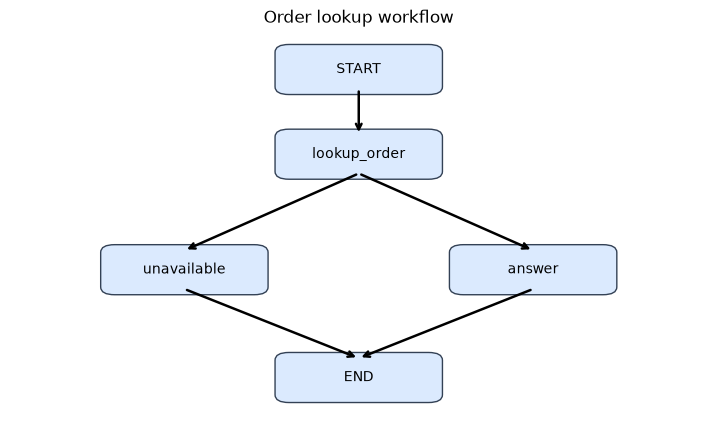

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from support_ops.graph import build_order_graph

support_graph = build_order_graph(orders, settings.demo.customer_id)
graph_view = support_graph.get_graph()

positions = {
    "__start__": (0.5, 0.90),
    "lookup_order": (0.5, 0.68),
    "answer": (0.75, 0.38),
    "unavailable": (0.25, 0.38),
    "__end__": (0.5, 0.10),
}
figure, axis = plt.subplots(figsize=(9, 5))
axis.set(xlim=(0, 1), ylim=(0, 1))
axis.axis("off")
for edge in graph_view.edges:
    x1, y1 = positions[edge.source]
    x2, y2 = positions[edge.target]
    axis.annotate("", xy=(x2, y2 + 0.05), xytext=(x1, y1 - 0.05), arrowprops={"arrowstyle": "->", "lw": 1.8})
for node_id in graph_view.nodes:
    x, y = positions[node_id]
    label = {"__start__": "START", "__end__": "END"}.get(node_id, node_id)
    box = FancyBboxPatch((x - 0.10, y - 0.045), 0.20, 0.09, boxstyle="round,pad=0.02", facecolor="#dbeafe", edgecolor="#334155")
    axis.add_patch(box)
    axis.text(x, y, label, ha="center", va="center")
axis.set_title("Order lookup workflow")
plt.show()

## 7. Follow a successful order through the graph

The next cell sends `ORD-1042` through the graph. It prints each node's update so you can see how the state grows. The path should be `lookup_order -> answer`. No API call is made.

In [9]:
final_state = {"order_id": settings.demo.order_id}
for update in support_graph.stream(final_state, stream_mode="updates"):
    node_name, changes = next(iter(update.items()))
    final_state.update(changes)
    print(f"After {node_name}:")
    print(json.dumps(final_state, ensure_ascii=False, indent=2))

assert final_state["order"]["found"] is True
assert settings.demo.order_id in final_state["answer"]
print("The accessible-order path passed.")

After lookup_order:
{
  "order_id": "ORD-1042",
  "order": {
    "found": true,
    "order_id": "ORD-1042",
    "product": "Wireless Headphones A1",
    "quantity": 1,
    "status": "shipped",
    "estimated_delivery": null
  }
}
After answer:
{
  "order_id": "ORD-1042",
  "order": {
    "found": true,
    "order_id": "ORD-1042",
    "product": "Wireless Headphones A1",
    "quantity": 1,
    "status": "shipped",
    "estimated_delivery": null
  },
  "answer": "Votre commande ORD-1042 est actuellement expédiée."
}
The accessible-order path passed.


## 8. Follow an unavailable order

The next cell runs two more order IDs: one belongs to another customer and one does not exist. Both should follow `lookup_order -> unavailable` and produce the same safe answer.

In [10]:
for order_id in (foreign_id, unknown_id):
    state = {"order_id": order_id}
    path = []
    for update in support_graph.stream(state, stream_mode="updates"):
        node_name, changes = next(iter(update.items()))
        path.append(node_name)
        state.update(changes)
    assert path == ["lookup_order", "unavailable"]
    assert state["order"] == unavailable
    print(json.dumps({"order_id": order_id, "path": path, "answer": state["answer"]}, ensure_ascii=False, indent=2))

{
  "order_id": "ORD-2099",
  "path": [
    "lookup_order",
    "unavailable"
  ],
  "answer": "Je ne peux pas accéder à cette commande."
}
{
  "order_id": "ORD-0",
  "path": [
    "lookup_order",
    "unavailable"
  ],
  "answer": "Je ne peux pas accéder à cette commande."
}


## Next stage

This notebook now shows the Groq probe and the first local LangGraph workflow. The next increment is controlled request classification, followed by a broader reviewed scenario set. Store-policy retrieval, persistent state, human approval and simulated actions belong to later stages. One successful live scenario is not a reliability benchmark.

Before sharing notebook outputs, inspect the final answer and keep only publishable synthetic results. Never print the model client, environment variables, raw provider exceptions or private reasoning.